# 第12章：网络表示、反向传播与训练诊断

**教师参考｜全书深化稿**

## 背景与数据
四点XOR和单隐藏单元手算是人工构造；Wine网络与固定验证样本比较。

## 本次要回答的问题
计算网络输出和梯度，检查有限差分；固定数据比较宽度、随机初值及训练曲线。

先写下预判，再运行，最后用实际结果解释；不需要结果符合预期才算成功。

In [1]:
from pathlib import Path
import os, sys
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "experiments/common.py").exists()
             and (p / "main.tex").exists()), None)
if root is None:
    raise RuntimeError("Open this notebook inside the extracted textbook project.")
sys.path.insert(0, str(root / "experiments"))
print("Project:", root)


Project: /mnt/data/book_v3


## 可检查的完整实验代码

下方与对应`experiments`脚本一致。共享的`common.py`只提供固定数据划分、保存表图和绘图设置；模型、目标、参数及比较规则在此明确写出。阅读函数后，再运行下一单元执行实验。

In [2]:
"""Chapter 12: an explicit XOR network, backprop check and training diagnostics."""
import numpy as np
import warnings
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import log_loss,accuracy_score
from sklearn.exceptions import ConvergenceWarning
from common import *

def run():
    X=np.array([[0,0],[0,1],[1,0],[1,1]],dtype=float);y=np.array([0,1,1,0])
    h1=np.maximum(X[:,0]-X[:,1],0);h2=np.maximum(X[:,1]-X[:,0],0)
    out=h1+h2;assert np.array_equal(out,y)
    table('ch12_xor',{'x1':X[:,0],'x2':X[:,1],'h1':h1,'h2':h2,'output':out,'target':y})
    def loss(t):
        w1,b1,w2,b2=t;pred=w2*max(0,w1*2+b1)+b2
        return .5*(pred-1)**2
    t=np.array([.5,0.,3.,0.]);g=np.array([12.,6.,2.,2.]);eps=1e-6
    gn=np.array([(loss(t+eps*np.eye(4)[j])-loss(t-eps*np.eye(4)[j]))/(2*eps) for j in range(4)])
    assert np.allclose(g,gn,rtol=1e-6)
    table('ch12_backprop',{'parameter':['w1','b1','w2','b2'],'analytic':g,'finite_difference':gn,'updated':t-.01*g})
    dump('ch12_update',{'loss_before':loss(t),'loss_after':loss(t-.01*g)})
    Xtr,Xva,ytr,yva,_=development_trainval('wine');rows=[];warning_log=[]
    for width in [4,12,32]:
        for seed in [0,1,2,3,4]:
            m=make_pipeline(StandardScaler(),MLPClassifier(hidden_layer_sizes=(width,),solver='lbfgs',alpha=.1,max_iter=1500,random_state=seed))
            with warnings.catch_warnings(record=True) as ws:
                warnings.simplefilter('always');m.fit(Xtr,ytr)
            warning_log.extend([{'width':width,'seed':seed,'message':str(w.message)} for w in ws])
            rows.append({'hidden_width':width,'seed':seed,'train_accuracy':m.score(Xtr,ytr),'validation_accuracy':m.score(Xva,yva),'validation_log_loss':log_loss(yva,m.predict_proba(Xva)),'iterations':m[-1].n_iter_})
    df=table('ch12_initializations',rows);summary=df.groupby('hidden_width').validation_accuracy.agg(['mean','std']).reset_index();table('ch12_initialization_summary',summary);show_result(summary);dump('ch12_warnings',warning_log)
    sc=StandardScaler().fit(Xtr);zt=sc.transform(Xtr);zv=sc.transform(Xva)
    m=MLPClassifier(hidden_layer_sizes=(12,),solver='sgd',learning_rate_init=.02,batch_size=20,alpha=.1,random_state=3,shuffle=True)
    records=[]
    for epoch in range(1,161):
        m.partial_fit(zt,ytr,classes=np.unique(ytr))
        records.append({'epoch':epoch,'train_log_loss':log_loss(ytr,m.predict_proba(zt)),'validation_log_loss':log_loss(yva,m.predict_proba(zv))})
    df=table('ch12_training_trace',records)
    plt.figure(figsize=(6.4,4));plt.plot(df.epoch,df.train_log_loss,label='training');plt.plot(df.epoch,df.validation_log_loss,label='validation');plt.xlabel('训练轮数 epoch');plt.ylabel('数据交叉熵（不含正则项）');plt.legend();figure('v3_ch12_training')

In [3]:
result = run()
if result is not None:
    print(result)

 hidden_width     mean  std
            4 0.972222  0.0
           12 0.972222  0.0
           32 0.972222  0.0


## 检查结果文件与图

下面显示该实验保存的图；所有坐标、样本与数值条件应与正文一致。数据表保存在`results/`。修改代码后，请另存结果或注明变化，不把新配置的输出与正文旧数值混用。

v3_ch12_training.png


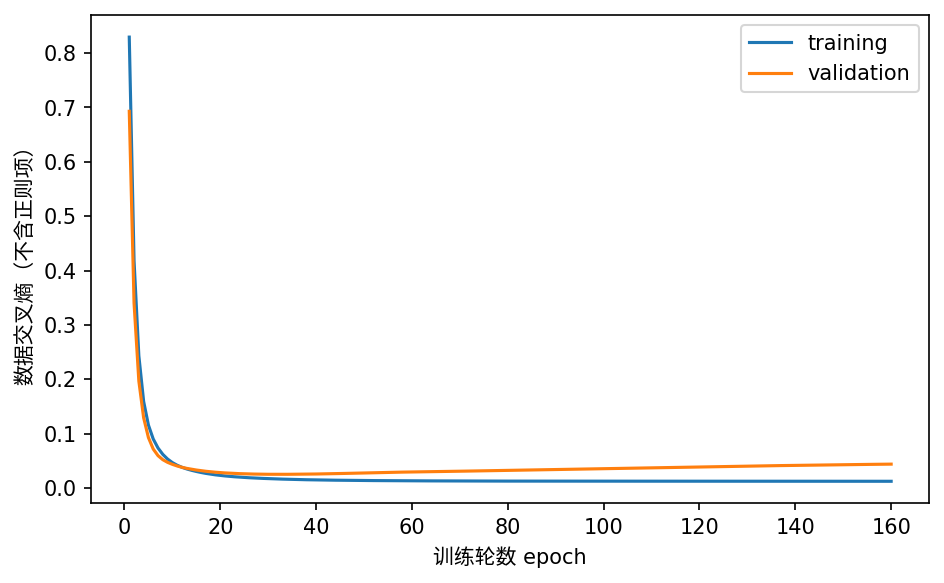

In [4]:
from IPython.display import display, Image
files = sorted((root / "figures").glob("v3_ch12_*.png"))
for path in files:
    print(path.name)
    display(Image(filename=str(path), width=720))
if not files:
    print("This experiment uses tables rather than a new figure.")

## 教师解释与核对

所有宽度准确率相同仍可有不同概率损失和迭代次数。表达一个函数不证明优化必然找到它。保留收敛警告并解释。

完整手算解答见`teacher_manual.pdf`。如果结果与这里的参考不同，先检查数据版本、划分、软件环境、目标归一化和随机状态，不要求学生人为调成相同分数。

**评分顺序：**问题与字段角色、数据划分、算法机制、实际结果分析、证据边界。代码能运行但无法说明一项输出的含义，不算完成理解目标。